# 16: Learning the rule: pose windows + classifiers

**Goal:** keep the real-time setting of notebook 15, but let a **classifier learn** when to raise the alarm instead of hand-written thresholds.

**Idea:** the rule of notebook 15 looks at a few signals (height, angle, speed) over the last fraction of a second. We give **the same signals** to a classifier, summarised over a **sliding window of the last 1 s**, and let it learn the combinations.

```
skeleton per frame ──▶ 8 signals ──▶ window of the last 1 s (min, max, mean, change) ──▶ classifier ──▶ P(fall) per frame
                                                                                                    │
                                                         alarm if P(fall) > thr for k frames in a row ◀┘
```

**Same test as notebook 15:** leave one subject out (5 groups), alarm within 3 s of the onset, every ADL alarm is a false alarm. The threshold `thr` and the length `k` are **also chosen on the training groups only**.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from fallcv import m1, pose, rule, urfd, windows
from fallcv.eval import evaluate, video_level

lab, onsets = urfd.labels(), urfd.fall_onsets()
groups = m1.load_groups()
seqs = urfd.sequences()
EXTRACTORS = ["mediapipe", "yolo"]
poses = {e: {s: pose.load(e, s) for s in seqs} for e in EXTRACTORS}
print(len(seqs), "videos,", len(onsets), "falls,", sum(len(poses["mediapipe"][s][0]) for s in seqs), "frames")

70 videos, 30 falls, 11936 frames


💡 **Interpretation:** same 70 videos and skeletons as notebook 15, for both pose extractors.

## Step 1: From frames to windows

Per frame we take the 8 signals the rule already computes (`src/fallcv/windows.py`):

| Signal | Meaning |
|---|---|
| `angle` | torso angle with the vertical |
| `aspect` | box width / height |
| `ratio` | box height / the person's upright height |
| `v_down`, `v_x` | vertical and horizontal speed of the hips (body heights per second) |
| `d_ratio`, `d_angle` | height and angle lost in the last 0.6 s |
| `cy_rel` | height of the hips in the image (0 top, 1 bottom) |

Each frame then becomes **one row**: for each signal its value now, min, max and mean over the last 1 s, and its change over the window. Frames where the person is not found stay **empty (NaN)**; `seen_frac` says how much of the window had a skeleton. Only **past** frames are used, so it still works live.

In [2]:
X, Y, USE = {}, {}, {}
for e in EXTRACTORS:
    X[e], Y[e], USE[e] = m1.build(e, win_s=1.0, onsets=onsets)
x = X["mediapipe"]["fall-02"]
on = onsets["fall-02"] - 1
print(x.shape[1], "numbers per frame")
x.iloc[[on - 30, on + 10, on + 40]][[c for c in x.columns if c.startswith(("ratio", "angle", "v_down"))]] \
    .set_axis(["1 s before onset", "0.3 s after", "1.3 s after"]).round(2)

41 numbers per frame


,angle_now,angle_min,angle_max,angle_mean,angle_delta,ratio_now,ratio_min,ratio_max,ratio_mean,ratio_delta,v_down_now,v_down_min,v_down_max,v_down_mean,v_down_delta
1 s before onset,0.74,0.20,2.71,0.86,NaN,0.98,0.98,1.00,0.98,NaN,0.02,0.00,0.03,0.01,NaN
0.3 s after,33.30,2.46,33.30,14.59,30.84,0.88,0.88,0.98,0.96,-0.09,-0.07,-0.07,0.02,0.00,-0.07
1.3 s after,87.66,34.60,87.66,62.91,53.06,0.46,0.36,0.87,0.58,-0.41,0.24,-0.06,1.01,0.47,0.30


💡 **Interpretation:** each frame becomes **41 numbers** (8 signals × 5 statistics + `seen_frac`). On `fall-02` the window shows the fall clearly: 1 s before the onset everything is flat (angle ≈ 1°, ratio ≈ 0.98); 1.3 s after, the angle reached 88°, the ratio lost 0.41 in the window and the hips reached a speed of 1.0. Empty cells (NaN) are the first frames, where the window is not full yet.

## Step 2: What the classifier must learn

Per frame target:
- **1** from the fall onset to 3 s later (the moment we want the alarm);
- **0** for every ADL frame and every fall frame **before** the onset;
- fall frames **after** those 3 s are **left out** of training: the person just lies there, which looks like lying down on purpose. An alarm then is late, not false.

training frames: 11932, positives: 1799 (15.1%)


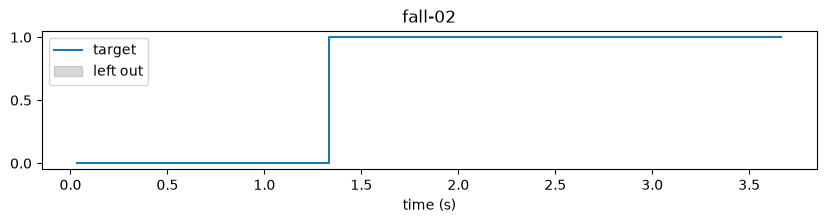

In [3]:
y_all = np.concatenate([Y["mediapipe"][s][USE["mediapipe"][s]] for s in seqs])
print(f"training frames: {len(y_all)}, positives: {y_all.sum()} ({y_all.mean():.1%})")
y, use = Y["mediapipe"]["fall-02"], USE["mediapipe"]["fall-02"]
t = np.arange(1, len(y) + 1) / urfd.FPS
plt.figure(figsize=(10, 1.8))
plt.step(t, y, where="post", label="target")
plt.fill_between(t, 0, 1, where=~use, color="grey", alpha=0.3, step="post", label="left out")
plt.title("fall-02"); plt.xlabel("time (s)"); plt.legend(loc="upper left"); plt.show()

💡 **Interpretation:** 11,932 training frames, **15%** positive. In `fall-02` the target is 1 for the 3 s after the onset, and the grey part (person lying after those 3 s) is not used for training.

## Step 3: Three classifiers

| Classifier | Why |
|---|---|
| **Logistic regression** | the simplest learned model: one weight per number |
| **Random forest** | many deep trees voting (bagging), as in notebooks 04-08 |
| **Gradient boosting** (`HistGradientBoosting`) | small trees built **one after another**, each fixing the previous errors; handles empty values natively |

`class_weight="balanced"` because only a few percent of frames are positive. Logistic regression and the random forest need the empty values filled (median), the boosting does not.

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

MODELS = {
    "logistic regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
    "random forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                                          n_jobs=-1, random_state=0)),
    "gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                        l2_regularization=1.0, class_weight="balanced", random_state=0),
}
KEEP = ["falls_hit", "adl_false_alarms", "fa_per_hour_adl", "pre_onset_false_alarms", "median_latency_s"]

def report(name, extractor, res, folds):
    _, s = evaluate(res, onsets, lab)
    return {"model": name, "extractor": extractor, **{k: s[k] for k in KEEP},
            "recall mean ± std": f"{folds.recall.mean():.2f} ± {folds.recall.std():.2f}", **video_level(res)}

runs, rows = {}, []
for name, model in MODELS.items():
    res, folds, proba = m1.loso(model, X["mediapipe"], Y["mediapipe"], USE["mediapipe"], groups, onsets, lab)
    runs[(name, "mediapipe")] = (res, folds, proba)
    rows.append(report(name, "mediapipe", res, folds))
pd.DataFrame(rows).round(3)

,model,extractor,falls_hit,adl_false_alarms,fa_per_hour_adl,pre_onset_false_alarms,median_latency_s,recall mean ± std,videos_right,video_accuracy,falls_caught,adl_videos_alarmed
0,logistic regression,mediapipe,27/30,7,84.554,0,0.967,0.90 ± 0.15,61/70,0.871,27/30,6/40
1,random forest,mediapipe,25/30,1,12.079,0,0.800,0.83 ± 0.12,64/70,0.914,25/30,1/40
2,gradient boosting,mediapipe,29/30,8,96.633,0,0.833,0.97 ± 0.07,61/70,0.871,29/30,8/40


💡 **Interpretation:** all 3 classifiers beat the rule (19/30) by far. **Gradient boosting catches the most falls (29/30)** but keeps 8 false alarms; **the random forest is the most careful: only 1 false alarm** (12 per hour) for 25/30 falls, so 64/70 videos right. Logistic regression is in between (27/30, 7). Like in notebooks 04-08 the classifiers trade falls for false alarms differently, so the choice depends on what matters more.

## Step 4: Does the pose extractor matter?

Same three classifiers on **YOLO11m-pose** skeletons.

In [5]:
for name, model in MODELS.items():
    res, folds, proba = m1.loso(model, X["yolo"], Y["yolo"], USE["yolo"], groups, onsets, lab)
    runs[(name, "yolo")] = (res, folds, proba)
    rows.append(report(name, "yolo", res, folds))
m1_table = pd.DataFrame(rows).round(3)
m1_table

,model,extractor,falls_hit,adl_false_alarms,fa_per_hour_adl,pre_onset_false_alarms,median_latency_s,recall mean ± std,videos_right,video_accuracy,falls_caught,adl_videos_alarmed
0,logistic regression,mediapipe,27/30,7,84.554,0,0.967,0.90 ± 0.15,61/70,0.871,27/30,6/40
1,random forest,mediapipe,25/30,1,12.079,0,0.800,0.83 ± 0.12,64/70,0.914,25/30,1/40
2,gradient boosting,mediapipe,29/30,8,96.633,0,0.833,0.97 ± 0.07,61/70,0.871,29/30,8/40
3,logistic regression,yolo,25/30,13,157.029,0,0.833,0.83 ± 0.29,53/70,0.757,25/30,12/40
4,random forest,yolo,26/30,1,12.079,2,0.883,0.87 ± 0.14,67/70,0.957,28/30,1/40
5,gradient boosting,yolo,29/30,6,72.475,0,0.800,0.97 ± 0.07,63/70,0.900,29/30,6/40


💡 **Interpretation:** the extractor matters for the weakest model but not much for the trees: with YOLO, **random forest reaches 26/30 falls with 1 false alarm, 67/70 videos**, the best balance so far and as good as the depth baseline of notebook 02 (67/70), which needed a depth camera and a much easier test. Boosting stays at 29/30 with 6 false alarms. Logistic regression gets worse with YOLO (13 false alarms). Note: the rule preferred MediaPipe, the learned models prefer YOLO, possibly because YOLO keeps a skeleton more often on lying people (checked in notebook 14).

## Step 5: The alarm rule chosen in each round (gradient boosting, MediaPipe)

In [6]:
runs[("gradient boosting", "mediapipe")][1].round(2)

,group,thr,k,falls_hit,recall,adl_fa
0,1,0.8,10,5/6,0.83,0
1,2,0.9,10,6/6,1.00,3
2,3,0.9,15,6/6,1.00,0
3,4,0.7,15,6/6,1.00,1
4,5,0.9,15,6/6,1.00,4


💡 **Interpretation:** the chosen rule is strict in every round: probability above **0.7 to 0.9 for 10 to 15 frames** (0.3 to 0.5 s). The training groups themselves ask for a long confirmation, which is how the model avoids alarms on short spikes. Groups 3 and 5, the worst for the rule (2/6), are now **6/6**.

## Step 6: P(fall) over time

The probability of the test-round model, on a fall and on the ADLs that still raise an alarm.

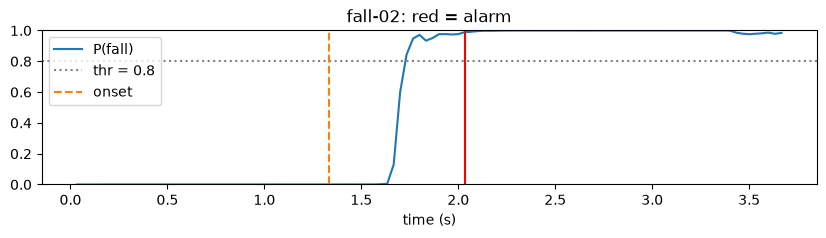

missed falls: ['fall-03'] | ADLs with an alarm: ['adl-16', 'adl-22', 'adl-23', 'adl-36', 'adl-32', 'adl-33', 'adl-34', 'adl-35']


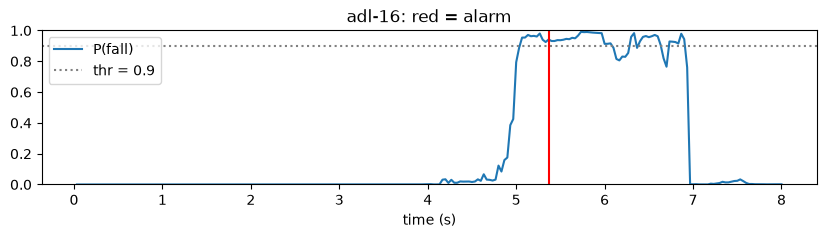

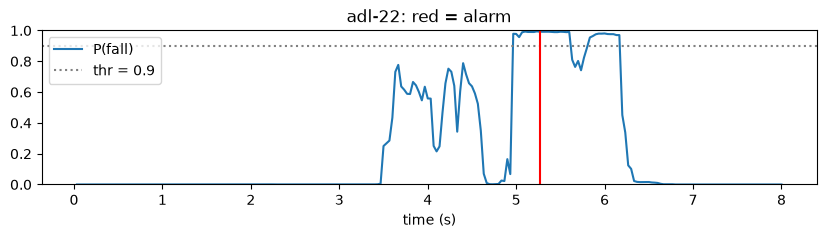

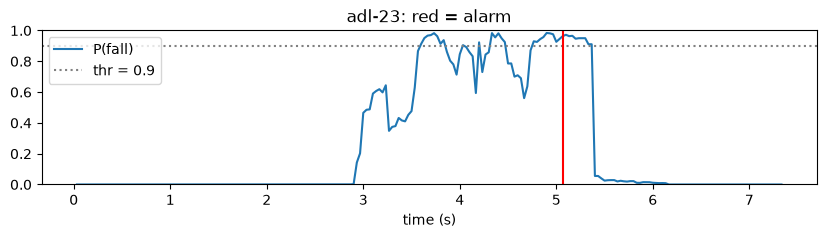

In [7]:
def plot_proba(seq, name="gradient boosting", extractor="mediapipe"):
    res, folds, proba = runs[(name, extractor)]
    p = proba[seq]
    t = np.arange(1, len(p) + 1) / urfd.FPS
    thr = folds.set_index("group").thr[groups[seq]]
    plt.figure(figsize=(10, 2))
    plt.plot(t, p, label="P(fall)"); plt.axhline(thr, ls=":", c="grey", label=f"thr = {thr}")
    if seq in onsets: plt.axvline(onsets[seq] / urfd.FPS, c="C1", ls="--", label="onset")
    for a in res[seq][1]: plt.axvline(a / urfd.FPS, c="red")
    plt.ylim(0, 1); plt.title(f"{seq}: red = alarm"); plt.xlabel("time (s)"); plt.legend(loc="upper left"); plt.show()

plot_proba("fall-02")
per_seq, _ = evaluate(runs[("gradient boosting", "mediapipe")][0], onsets, lab)
fa = per_seq[(per_seq.kind == "adl") & (per_seq.false_alarms > 0)].seq.tolist()
missed = per_seq[(per_seq.kind == "fall") & ~per_seq.hit.astype(bool)].seq.tolist()
print("missed falls:", missed, "| ADLs with an alarm:", fa)
for s in fa[:3]:
    plot_proba(s)

💡 **Interpretation:** on `fall-02` the probability jumps from 0 to 1 between 1.65 and 1.85 s, and the alarm comes at **2.0 s**, 0.7 s after the onset (the rule needed 1.4 s). The false alarms are not random: `adl-16` and `adl-22` come from the **dark room** session (group 2, also the hardest for person detection in notebook 03), where the person goes down and the probability stays above 0.9 for 1 to 2 s. The only missed fall is `fall-03`, one of the long videos that every method of notebooks 02-08 also gets wrong.

## Step 7: Which signals does the model use?

Importance of each signal in a random forest trained on all 70 videos (summed over its 5 window statistics). This is only to **understand** the model, not a test score.

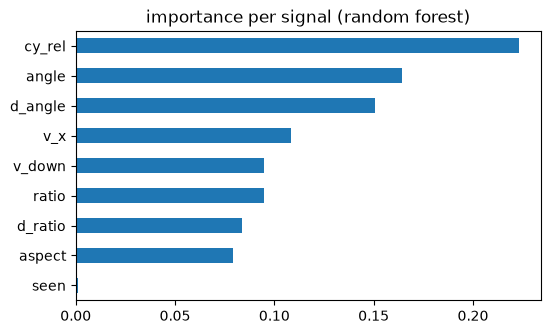

In [8]:
rf = MODELS["random forest"]
from sklearn.base import clone
Xa = pd.concat([X["mediapipe"][s][USE["mediapipe"][s]] for s in seqs])
rf_all = clone(rf).fit(Xa, y_all)
imp = pd.Series(rf_all[-1].feature_importances_, index=Xa.columns)
by_signal = imp.groupby(imp.index.str.rsplit("_", n=1).str[0]).sum().sort_values()
by_signal.plot.barh(figsize=(6, 3.5), title="importance per signal (random forest)"); plt.show()

💡 **Interpretation:** the most used signal is **`cy_rel`, the height of the hips in the image**, then the torso **angle** and how fast it changes. Speeds and height ratio come next. `cy_rel` works because the camera never moves in this dataset; in another room it would need re-training. This is the same limit as the *hips low* rule of notebook 10.

## Step 8: Rule (notebook 15) vs learned rule (this notebook)

Everything below is **leave one subject out** and **real time**.

In [9]:
b0_rows = []
for e in EXTRACTORS:
    # rerun notebook 15's fair protocol here so the table is self-contained
    GRID = [replace(rule.Params(), drop_ratio=d, confirm_s=c) for d in [0.3, 0.4, 0.5] for c in [0.3, 0.5, 1.0]]
    allruns = [{s: rule.run(kp, box, p)[:2] for s, (kp, box) in poses[e].items()} for p in GRID]
    merged = {}
    for g in sorted(groups.unique()):
        train = [s for s in seqs if groups[s] != g]
        sc = lambda r: (lambda d: d.hit.fillna(False).astype(int).sum() - d.false_alarms.sum())(
            evaluate({s: r[s] for s in train}, onsets, lab)[0])
        best = max(range(len(GRID)), key=lambda i: sc(allruns[i]))
        merged.update({s: allruns[best][s] for s in seqs if groups[s] == g})
    _, s = evaluate(merged, onsets, lab)
    b0_rows.append({"method": "B0 rule (nb 15)", "extractor": e, **{k: s[k] for k in KEEP}, **video_level(merged)})
best = m1_table.assign(method="M1 " + m1_table.model).drop(columns=["model", "recall mean ± std"])
compare = pd.concat([pd.DataFrame(b0_rows), best], ignore_index=True)
compare[["method", "extractor", "falls_hit", "adl_false_alarms", "fa_per_hour_adl", "median_latency_s",
         "videos_right"]].round(2)

,method,extractor,falls_hit,adl_false_alarms,fa_per_hour_adl,median_latency_s,videos_right
0,B0 rule (nb 15),mediapipe,19/30,7,84.55,1.20,52/70
1,B0 rule (nb 15),yolo,14/30,11,132.87,1.42,43/70
2,M1 logistic regression,mediapipe,27/30,7,84.55,0.97,61/70
3,M1 random forest,mediapipe,25/30,1,12.08,0.80,64/70
4,M1 gradient boosting,mediapipe,29/30,8,96.63,0.83,61/70
5,M1 logistic regression,yolo,25/30,13,157.03,0.83,53/70
6,M1 random forest,yolo,26/30,1,12.08,0.88,67/70
7,M1 gradient boosting,yolo,29/30,6,72.47,0.80,63/70


💡 **Interpretation:** under the same fair, real-time test, learning the decision lifts the score from **19/30 to 25-29/30 falls**. The best two options are **gradient boosting** (most falls, 29/30, about 6-8 false alarms) and **random forest + YOLO** (26/30 falls in time, only 1 false alarm, 67/70 videos). The latency also drops from 1.2 s to about 0.8 s.

## What we learned

1. **Learning the rule works:** same skeletons, same signals, same real-time test, but a classifier on 1 s windows catches **25 to 29 of 30 falls** against 19 for the hand-written rule, and the alarm comes faster (≈ 0.8 s after the onset instead of 1.2 s).
2. **Best options:**
   - **gradient boosting**: 29/30 falls, 6 (YOLO) to 8 (MediaPipe) false alarms;
   - **random forest + YOLO**: 26/30 falls in time, **1 false alarm**, **67/70 videos**, the best balance and the best video score under a leave-one-subject-out test.
3. **The weakest actors are fixed:** groups 3 and 5 go from 2/6 to 6/6.
4. **Remaining false alarms** come from the dark-room session (`adl-16`, `22`, `23`) and from people going down to the floor on purpose (`adl-32`…`36`).
5. **Limits:** the most used signal is the hip height in the image, which depends on the camera position; all numbers come from 70 videos and 5 actors, so one video is 1.4 points.

**Next:** compare the pose extractors in detail (MediaPipe, YOLO, RTMPose) and study the remaining false alarms.